# Distance, networks and accessibility

How can we describe movement through geographic space?

The distance between two places depends on how we measure it. A straight line connects their coordinates, while a walking route follows the connections represented in a street network.

We travel from **Sanbapolis to BUC in Trento**. We use this example to understand how OpenStreetMap data become a graph, how a route is calculated and how distance becomes an estimated walking time. We then explore which network locations are reachable from each place within a distance or time budget.

Finally, pharmacy observations provide a separate example of proximity graphs with City2Graph. Their edges describe distance relationships, not streets.

## Goals of the tutorial

- Understand graph nodes, edges, direction and weights.
- Inspect a street network with OSMnx, NetworkX and GeoPandas.
- Compare planar, geodesic and network distances.
- Connect geographic locations to network nodes.
- Calculate and inspect a shortest path.
- Estimate walking time using an explicit speed assumption.
- Explore isodistances and approximate isochrones.
- Compare proximity graphs using City2Graph.
- Explain how data and modelling choices affect the results.

## Based on open data from

- [OpenStreetMap](https://www.openstreetmap.org/) — walking-network data.
- [Trentino health-service pharmacy data](https://servizi.apss.tn.it/opendata/FARM001.csv) — locations for the City2Graph examples, distributed as a [course snapshot](https://github.com/napo/geospatial-data-science-2026/tree/main/data).

## Requirements

Basic Python and GeoPandas; vector geometries, coordinate reference systems, spatial relationships and distance units; the OpenStreetMap data model.

## Starting question

Look at Sanbapolis and BUC on the map. **Which route would you take on foot, and what information would a computer need to calculate it?**

## Setup

In [ ]:
%pip install -q "geopandas>=1.2,<2" "pandas>=2.2,<4" "osmnx>=2.1,<3" "networkx>=3.4,<4" "folium>=0.20,<1" "mapclassify>=2.8,<3" "matplotlib>=3.10,<4" "requests>=2.32,<3" scipy scikit-learn "city2graph==1.0.1" pyrosm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [ ]:
from pathlib import Path
import json
import importlib.metadata
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import osmnx as ox
import networkx as nx
from IPython.display import display
from shapely.geometry import Point, LineString, box
from pyproj import Geod
import matplotlib.pyplot as plt

DATA = Path("data")
DATA.mkdir(exist_ok=True)
DATA_REF = "main"
BASE_URL = f"https://raw.githubusercontent.com/napo/geospatial-data-science-2026/{DATA_REF}/data/"


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Start from two known places

[Sanbapolis](https://www.openstreetmap.org/?mlat=46.04717&mlon=11.13261#map=18/46.04717/11.13261): longitude 11.13261, latitude 46.04717.

[BUC](https://www.openstreetmap.org/?mlat=46.05968&mlon=11.11552#map=18/46.05968/11.11552): longitude 11.11552, latitude 46.05968.

These explicit teaching coordinates come from the old tutorial. Inspect their placement on the map: they are not automatically verified entrances on the walking graph. We retain the variable name `origins` because later both places become starting points for reachability.

### Create and inspect the two points

Inspect input coordinates and geometry before choosing a distance model.

**AI prompt:** Build origins using longitude as x and latitude as y. Show the CRS, attributes and geometries.

**Look at the result:** How does the geometry relate to the two coordinate columns?

In [ ]:
origin_rows = [
    {"origin_id": "Sanbapolis", "longitude": 11.13261, "latitude": 46.04717},
    {"origin_id": "BUC", "longitude": 11.11552, "latitude": 46.05968},
]
origins = gpd.GeoDataFrame(
    origin_rows,
    geometry=gpd.points_from_xy(
        [row["longitude"] for row in origin_rows],
        [row["latitude"] for row in origin_rows],
    ),
    crs=4326,
)
origins_m = (
    origins.to_crs(32632).set_index("origin_id", drop=False).rename_axis("origin_index")
)

display(origins)
print("CRS:", origins.crs)


,origin_id,longitude,latitude,geometry
0,Sanbapolis,11.13261,46.04717,POINT (11.13261 46.04717)
1,BUC,11.11552,46.05968,POINT (11.11552 46.05968)


CRS: EPSG:4326


### Locate both places on HOT OSM

Start with a geographic question, not a routing command.

**AI prompt:** Map origins on HOT OSM using origin_id as tooltip.

**Look at the result:** Which barriers, crossings and connections might affect a walk between these places?

In [ ]:
m = origins.explore(
    tiles="OpenStreetMap.HOT",
    color="orange",
    tooltip=["origin_id"],
    marker_kwds={"radius": 7},
)
display(m)


### Measure straight-line distance

Use the same two endpoints to compare projected and ellipsoidal distance.

**AI prompt:** Define sanbapolis and buc from origins and compute planar metres in EPSG:32632 and a WGS84 geodesic distance.

**Look at the result:** Neither method follows streets. Do not calculate metre distances from degree coordinates.

In [ ]:
sanbapolis = origins.loc[origins["origin_id"].eq("Sanbapolis")].geometry.iloc[0]
buc = origins.loc[origins["origin_id"].eq("BUC")].geometry.iloc[0]
air_m = origins_m.loc["Sanbapolis"].geometry.distance(origins_m.loc["BUC"].geometry)
_, _, geodesic_m = Geod(ellps="WGS84").inv(sanbapolis.x, sanbapolis.y, buc.x, buc.y)
print("Projected straight-line metres:", air_m)
print("Ellipsoidal geodesic metres:", geodesic_m)


Projected straight-line metres: 1918.9145017222302
Ellipsoidal geodesic metres: 1919.0451770461316


### Read the direction

Recover the bearing example from the old tutorial using these same places.

**AI prompt:** Calculate the bearing from Sanbapolis to BUC with OSMnx. Explain the argument order.

**Look at the result:** Bearing is a direction in degrees clockwise from north, not a distance or a route.

In [ ]:
bearing = ox.bearing.calculate_bearing(sanbapolis.y, sanbapolis.x, buc.y, buc.x)
print("Sanbapolis → BUC bearing:", bearing, "degrees clockwise from north")


Sanbapolis → BUC bearing: 316.5334036303139 degrees clockwise from north


### Show the direction on a compass

North is zero degrees; angles increase clockwise. The arrow points towards BUC. It does not describe the walking route.

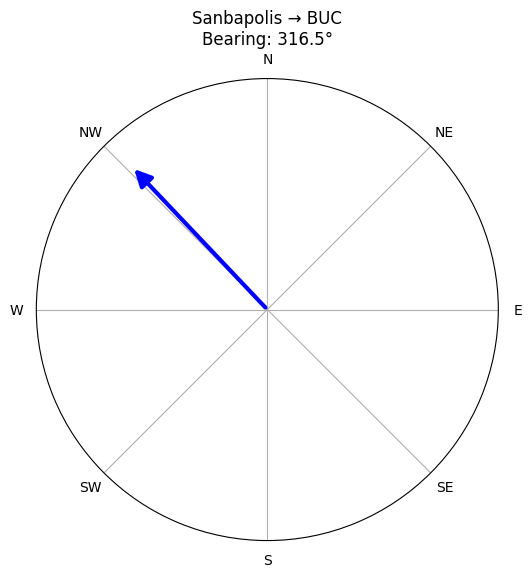

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
ax.set_xticklabels(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
ax.set_ylim(0, 1)
ax.set_yticks([])
angle = np.deg2rad(bearing)
ax.annotate(
    "",
    xy=(angle, 0.85),
    xytext=(angle, 0),
    arrowprops={"arrowstyle": "-|>", "color": "blue", "lw": 3, "mutation_scale": 25},
)
ax.set_title(f"Sanbapolis → BUC\nBearing: {bearing:.1f}°", pad=25)
plt.show()


## 2. Represent a walking network as a graph

How can we calculate a walking route from Sanbapolis to BUC?

Coordinates locate the places. We also need streets, paths and information about how they connect. We download the Trento OpenStreetMap extract in PBF format, use Pyrosm to extract a walking network and construct a NetworkX graph. We then investigate that graph with OSMnx.

The PBF contains OSM objects, not a ready-made walking graph. The file is a course snapshot distributed through GitHub. Original source: OpenStreetMap municipal extract distributed by Wikimedia Italia.

### Download the OSM extract

PBF is a compact binary format for OpenStreetMap data. Download the file and inspect its size before opening it.

**AI prompt:** Download the original Trento PBF from the course repository with requests, save its bytes in DATA and print the URL and byte count. Do not load a previously built graph.

In [ ]:
from pyrosm import OSM

pbf_url = BASE_URL + "trento.osm.pbf"
pbf_path = DATA / "trento.osm.pbf"
print("Download URL:", pbf_url)
response = requests.get(pbf_url, timeout=60)
response.raise_for_status()
pbf_path.write_bytes(response.content)
print("Downloaded:", pbf_path)
print("File size:", pbf_path.stat().st_size, "bytes")


Download URL: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/trento.osm.pbf
Downloaded: data/trento.osm.pbf
File size: 5792701 bytes


### Extract the walking network

Open the PBF and select the walking network. With nodes=True, Pyrosm returns two geographic tables: nodes and the edges connecting them.

**AI prompt:** Initialise OSM from pbf_path. Extract pbf_nodes and pbf_edges with network_type="walking" and nodes=True. Do not overwrite the original PBF.

In [ ]:
osm = OSM(str(pbf_path))
pbf_nodes, pbf_edges = osm.get_network(network_type="walking", nodes=True)


Reading trento.osm.pbf took 00:07


In [ ]:
pbf_nodes.head()


,lon,lat,tags,visible,version,timestamp,changeset,id,geometry
0,11.115193,45.982531,None,True,4,1546033347,0,9208190,POINT (11.11519 45.98253)
1,11.114479,45.983527,None,True,4,1546033347,0,9204768,POINT (11.11448 45.98353)
2,11.114315,45.983827,None,True,3,1546033348,0,324159698,POINT (11.11432 45.98383)
3,11.114212,45.984134,None,True,4,1546033347,0,9211570,POINT (11.11421 45.98413)
4,11.132761,46.014208,None,True,7,1593370673,0,130030749,POINT (11.13276 46.01421)


In [ ]:
pbf_edges.head()


,access,bicycle,bridge,busway,cycleway,foot,footway,highway,junction,lanes,...,visible,id,timestamp,version,tags,osm_type,geometry,u,v,length
0,NaN,no,NaN,NaN,NaN,NaN,NaN,trunk,NaN,2,...,True,2132537,1760017660,38,"{""agricultural"":""no"",""expressway"":""yes"",""moped...",way,"LINESTRING (11.11519 45.98253, 11.11448 45.98353)",9208190,9204768,123.747
1,NaN,no,NaN,NaN,NaN,NaN,NaN,trunk,NaN,2,...,True,2132537,1760017660,38,"{""agricultural"":""no"",""expressway"":""yes"",""moped...",way,"LINESTRING (11.11448 45.98353, 11.11432 45.98383)",9204768,324159698,35.658
2,NaN,no,NaN,NaN,NaN,NaN,NaN,trunk,NaN,2,...,True,2132537,1760017660,38,"{""agricultural"":""no"",""expressway"":""yes"",""moped...",way,"LINESTRING (11.11432 45.98383, 11.11421 45.98413)",324159698,9211570,35.135
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,residential,NaN,NaN,...,True,13858908,1626013922,14,NaN,way,"LINESTRING (11.13276 46.01421, 11.13276 46.01401)",130030749,428762163,22.043
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,residential,NaN,NaN,...,True,13858908,1626013922,14,NaN,way,"LINESTRING (11.13276 46.01401, 11.1327 46.01387)",428762163,955304892,15.657


### Read the connections

Each edge has a starting node u and an ending node v. These refer to the id column of the node table. Inspect the length and geometry of each connection before building a graph.

In [ ]:
display(pbf_nodes[["id", "geometry"]].head())
display(pbf_edges[["u", "v", "highway", "length", "geometry"]].head())


,id,geometry
0,9208190,POINT (11.11519 45.98253)
1,9204768,POINT (11.11448 45.98353)
2,324159698,POINT (11.11432 45.98383)
3,9211570,POINT (11.11421 45.98413)
4,130030749,POINT (11.13276 46.01421)


,u,v,highway,length,geometry
0,9208190,9204768,trunk,123.747,"LINESTRING (11.11519 45.98253, 11.11448 45.98353)"
1,9204768,324159698,trunk,35.658,"LINESTRING (11.11448 45.98353, 11.11432 45.98383)"
2,324159698,9211570,trunk,35.135,"LINESTRING (11.11432 45.98383, 11.11421 45.98413)"
3,130030749,428762163,residential,22.043,"LINESTRING (11.13276 46.01421, 11.13276 46.01401)"
4,428762163,955304892,residential,15.657,"LINESTRING (11.13276 46.01401, 11.1327 46.01387)"


### Look at the extracted network

Map the edges on HOT OSM and add Sanbapolis and BUC. Which streets and paths are included? Are both places inside the extract?

In [ ]:
pbf_map = pbf_edges.explore(
    tiles="OpenStreetMap.HOT",
    color="blue",
    name="Extracted walking edges",
    tooltip=["highway", "length"],
    popup=False,
    style_kwds={"weight": 2},
)
origins.explore(
    m=pbf_map,
    color="orange",
    name="Sanbapolis and BUC",
    tooltip=["origin_id"],
    marker_kwds={"radius": 8},
)
west, south, east, north = origins.to_crs(4326).total_bounds
pbf_map.fit_bounds([[south, west], [north, east]], padding=(40, 40))
folium.LayerControl(collapsed=False).add_to(pbf_map)
display(pbf_map)


### Construct the graph

Convert the node and edge tables into a NetworkX graph compatible with OSMnx. We retain disconnected components so missing connections remain visible.

For walking networks, Pyrosm models connections in both directions. This is an explicit assumption: pedestrian one-way restrictions and current access conditions are not fully represented. The walking selection also needs interpretation for individual accessibility needs.

**AI prompt:** Convert pbf_nodes and pbf_edges with osm.to_graph, graph_type="networkx" and retain_all=True. Inspect the graph type and size.

In [ ]:
G = osm.to_graph(pbf_nodes, pbf_edges, graph_type="networkx", retain_all=True)
print("Graph type:", type(G))
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())


A **MultiDiGraph** has directed edges and can contain several edges between the same pair of nodes. In this walking model, connections are represented in both directions. We can now inspect their attributes and extract geographic tables from the graph.

[Pyrosm graph documentation](https://pyrosm.readthedocs.io/en/latest/graphs.html) · [OSMnx](https://osmnx.readthedocs.io/en/stable/)

### Inspect a node

Select one node. Its identifier tells us which node it is; its attributes tell us about it.

In [ ]:
node_id = next(iter(G.nodes))
print("Node ID:", node_id)


In [ ]:
G.nodes[node_id]


Look at x and y. In this unprojected graph, x is longitude and y is latitude. These coordinates locate the node; they are not its identifier.

In [ ]:
print("Longitude:", G.nodes[node_id]["x"])
print("Latitude:", G.nodes[node_id]["y"])


### Inspect an edge

An edge connects a starting node u to an ending node v. A key distinguishes parallel edges between those nodes.

In [ ]:
u, v, key = next(iter(G.edges(keys=True)))
print("Starting node:", u)
print("Ending node:", v)
print("Edge key:", key)


In [ ]:
G.edges[u, v, key]


Look for an OpenStreetMap identifier, highway classification, name and length. Not every edge has the same attributes. The length attribute is expressed in metres.

### Convert the graph into geographic tables

Extract a GeoDataFrame for nodes and one for edges. We can inspect them using familiar GeoPandas operations.

**AI prompt:** Convert G to nodes and edges GeoDataFrames. Inspect their first rows, geometry types and CRS.

In [ ]:
nodes, edges = ox.convert.graph_to_gdfs(G)


In [ ]:
nodes.head()


In [ ]:
edges.head()


In [ ]:
print("Node geometry types:", nodes.geometry.geom_type.unique())
print("Edge geometry types:", edges.geometry.geom_type.unique())
print("Node CRS:", nodes.crs)
print("Edge CRS:", edges.crs)


### Project the network

Project the graph to EPSG:32632 to work with metre-based coordinates in the Trento area. Keep G unchanged and name the projected graph G_m.

Compare the same node before and after projection. Its location stays the same; its numerical representation changes.

In [ ]:
G_m = ox.projection.project_graph(G, to_crs="EPSG:32632")
nodes_m, edges_m = ox.convert.graph_to_gdfs(G_m)


In [ ]:
print("Before projection:", nodes.loc[node_id, "geometry"])
print("After projection:", nodes_m.loc[node_id, "geometry"])
print("Projected CRS:", nodes_m.crs)


### Inspect the edge table

The edge index preserves u, v and key. Inspect the geometry and the length attribute. A projected line length and OSMnx's accumulated length attribute need not be identical; we will explicitly use the length attribute for routing.

In [ ]:
edges_m[["osmid", "highway", "length", "geometry"]].head()


### Explore the walking network

Display edges on HOT OSM and add Sanbapolis and BUC. Inspect streets and paths near each place. Are the original points directly on the graph?

**AI prompt:** Map edges and origins on a HOT basemap, with separate layers, highway and length tooltips, and a layer control. Start the map around the two places.

In [ ]:
network_map = edges.explore(
    tiles="OpenStreetMap.HOT",
    color="blue",
    name="Walking network",
    tooltip=["highway", "length"],
    popup=False,
    style_kwds={"weight": 2},
)
origins.explore(
    m=network_map,
    color="orange",
    name="Sanbapolis and BUC",
    tooltip=["origin_id"],
    marker_kwds={"radius": 8},
)
west, south, east, north = origins.to_crs(4326).total_bounds
network_map.fit_bounds([[south, west], [north, east]], padding=(40, 40))
folium.LayerControl(collapsed=False).add_to(network_map)
display(network_map)


### Before calculating a route

We have G, G_m and their node/edge tables. The original Sanbapolis and BUC points may not coincide with graph nodes. Next we inspect their nearest-node assignments.

The graph is a walking model derived from mapped data. Missing connections, access restrictions and conditions on the ground can affect an actual journey. OSMnx's walk selection is not a guarantee of current access or suitability for every pedestrian.

Data: © OpenStreetMap contributors, [ODbL](https://www.openstreetmap.org/copyright). Tools: [OSMnx](https://osmnx.readthedocs.io/en/stable/) · [NetworkX](https://networkx.org/).

## 3. Connect the places to the graph

### Connect origins to nodes

First inspect one nearest-node result, then build the full assignment tables.

**AI prompt:** Use the projected Sanbapolis point to obtain its nearest node and offset with OSMnx.

**Look at the result:** X and Y are now projected metres, not longitude and latitude.

In [ ]:
origin_example = origins_m.loc["Sanbapolis"].geometry
nearest_node, offset = ox.distance.nearest_nodes(
    G_m, X=origin_example.x, Y=origin_example.y, return_dist=True
)
print("Nearest graph node:", nearest_node, "Point-to-node offset in metres:", offset)


Nearest graph node: 428647170 Point-to-node offset in metres: 1.5535532566528913


### Inspect both assignments

Keep each source location and its graph node distinct.

**AI prompt:** Find nearest nodes and offsets for both origins_m points. Build origin_snap and flag offsets above 100 metres.

**Look at the result:** A small offset can still cross a wall or barrier. The flag is a review rule, not proof of access.

In [ ]:
MAX_OFFSET_M = 100.0
origin_node_ids, origin_offsets = ox.distance.nearest_nodes(
    G_m,
    X=origins_m.geometry.x.to_numpy(),
    Y=origins_m.geometry.y.to_numpy(),
    return_dist=True,
)
origin_snap = pd.DataFrame(
    {
        "origin_id": origins_m["origin_id"].to_numpy(),
        "node": origin_node_ids,
        "offset_m": origin_offsets,
    }
).set_index("origin_id", drop=False)
origin_snap["offset_ok"] = origin_snap["offset_m"].le(MAX_OFFSET_M)
display(origin_snap)


,origin_id,node,offset_m,offset_ok
origin_id,,,,
Sanbapolis,Sanbapolis,428647170,1.553553,True
BUC,BUC,9219825910,0.168459,True


### Map the original positions and graph nodes

Make snapping visible instead of hiding it inside routing.

**AI prompt:** Map original origins in orange, assigned graph nodes in blue and straight point-to-node connectors as dashed red lines.

**Look at the result:** Inspect each connector on the basemap. Does the proposed connection make physical sense?

In [ ]:
snap_nodes = nodes_m.loc[origin_snap["node"].tolist()].copy()
snap_nodes["place"] = origin_snap["origin_id"].tolist()
connector_rows = []
for oid, row in origin_snap.iterrows():
    connector_rows.append(
        {
            "place": oid,
            "offset_m": row["offset_m"],
            "geometry": LineString(
                [origins_m.loc[oid].geometry, nodes_m.loc[row["node"]].geometry]
            ),
        }
    )
connectors = gpd.GeoDataFrame(connector_rows, geometry="geometry", crs=32632)
m = origins.explore(
    tiles="OpenStreetMap.HOT",
    color="orange",
    name="Original places",
    tooltip=["origin_id"],
)
snap_nodes.to_crs(4326).explore(
    m=m, color="blue", name="Assigned nodes", tooltip=["place"]
)
connectors.to_crs(4326).explore(
    m=m,
    color="red",
    name="Hypothetical connectors",
    tooltip=["place", "offset_m"],
    style_kwds={"dashArray": "5,5"},
)
folium.LayerControl().add_to(m)
display(m)


## 4. One route, examined step by step

### Ask for a route between the two known places

Start with one concrete pair, before all origin–pharmacy combinations.

**AI prompt:** Find the shortest length route from Sanbapolis to BUC. Print the node sequence.

**Look at the result:** The result is a sequence of graph nodes, not a list of all nearby edges.

In [ ]:
start_node = origin_snap.loc["Sanbapolis", "node"]
end_node = origin_snap.loc["BUC", "node"]
route = ox.routing.shortest_path(G_m, start_node, end_node, weight="length")
print("Route node IDs:", route)


Route node IDs: [np.int64(428647170), 2858849118, 7158641130, 7158641116, 7158641118, 7194196987, 7158641107, 1755263894, 9653566312, 6418293000, 7194210873, 7194210871, 7194210870, 7194210865, 7194210866, 8977581981, 8977581980, 8977581975, 8977581971, 12170464938, 12170464939, 7235152228, 12170464957, 270725771, 270725769, 12170437376, 2665367753, 5590985311, 12170437385, 2235776588, 258912662, 258009162, 1555876676, 430169338, 12059814555, 12059814537, 12059814550, 12059814549, 12059814548, 12059814547, 12059814544, 12059814542, 12059814541, 12059814540, 3123681044, 3123681055, 3123681064, 1458146119, 3123693720, 3123693957, 258938361, 251369539, 251369558, 261240788, 3120467620, 277357928, 3120467553, 3120467588, 261710682, 13653441414, 3120467163, 9204230, 3110536905, 1388563834, 1388563854, 6719052501, 433738325, 277406945, 2487319582, 260914996, 2510748559, 13161888086, 9460057519, 12040098844, 2475915108, 2407322951, 5494719660, 4446398943, 9219825918, np.int64(9219825910)]


### Extract and sum the actual route edges

Use the same weight for selecting the path and its parallel edges.

**AI prompt:** Convert route to route_edges with weight=length. Sum length and compare with NetworkX shortest_path_length. Handle a missing or zero-edge route.

**Look at the result:** Do not sum every edge whose endpoint appears somewhere in route.

In [ ]:
route_edges = edges_m.iloc[0:0].copy()
if route is None:
    route_length = np.nan
    print("No route in this graph.")
else:
    if len(route) > 1:
        route_edges = ox.routing.route_to_gdf(G_m, route, weight="length")
    route_length = float(route_edges["length"].sum())
    expected = nx.shortest_path_length(G_m, start_node, end_node, weight="length")
    assert np.isclose(route_length, expected)
    display(route_edges[["osmid", "length"]])
    print("Node-to-node route metres:", route_length)


,,,osmid,length
u,v,key,,
428647170,2858849118,0,36867850,25.666
2858849118,7158641130,0,766477254,5.791
7158641130,7158641116,0,766477253,31.091
7158641116,7158641118,0,766477253,141.728
7158641118,7194196987,0,766477253,3.959
...,...,...,...,...
2475915108,2407322951,0,239818744,100.191
2407322951,5494719660,0,239818744,10.954
5494719660,4446398943,0,"[1381163533, 1381163533, 1381163533, 138116353...",171.060


Node-to-node route metres: 3046.669


### Compare the route with its straight-line alternative

Both alternatives must use documented endpoints.

**AI prompt:** Map the route in blue and the point-to-point straight line in dashed red on HOT OSM. Include orange origin markers.

**Look at the result:** The network route starts and ends at snapped nodes; the red line joins original observations. Offsets remain separate.

In [ ]:
route_map = origins.explore(
    tiles="OpenStreetMap.HOT",
    color="orange",
    name="Original points",
    tooltip=["origin_id"],
)
if not route_edges.empty:
    route_edges.to_crs(4326).explore(
        m=route_map,
        color="blue",
        name="Network route",
        tooltip=["length"],
        style_kwds={"weight": 5},
    )
straight_line = gpd.GeoSeries(
    [LineString([origins_m.loc["Sanbapolis"].geometry, origins_m.loc["BUC"].geometry])],
    crs=32632,
)
straight_line.to_crs(4326).explore(
    m=route_map,
    color="red",
    name="Straight line",
    style_kwds={"dashArray": "6,6", "weight": 3},
)
folium.LayerControl().add_to(route_map)
display(route_map)


### Add a walking-time assumption

A speed model turns length into estimated time, not measured time.

**AI prompt:** Assign walk_s from length using a declared 4 km/h. Report minutes for the example route. Do not use vehicle speed limits.

**Look at the result:** One kilometre takes 15 minutes at this uniform speed; waiting, slope and access conditions are omitted.

In [ ]:
WALK_KMH = 4.0
metres_per_second = WALK_KMH * 1000 / 3600
for u, v, key, attributes in G_m.edges(keys=True, data=True):
    attributes["walk_s"] = attributes["length"] / metres_per_second
print("Example node-to-node route minutes:", route_length / metres_per_second / 60)
print("At uniform speed, shortest length and shortest time select equivalent costs.")


Example node-to-node route minutes: 45.70003499999999
At uniform speed, shortest length and shortest time select equivalent costs.


### Keep point distance, node distance and connectors separate

Produce one comparison table for the actual pair.

**AI prompt:** Build route_comparison with air distance, node-to-node route distance, connector offsets and estimated time. State whether connections require review.

**Look at the result:** Adding straight connectors is a hypothetical model, not a verified entrance-to-entrance route.

In [ ]:
connector_m = float(origin_snap["offset_m"].sum())
connections_review = not bool(origin_snap["offset_ok"].all())
route_comparison = pd.DataFrame(
    [
        {
            "origin": "Sanbapolis",
            "destination": "BUC",
            "air_m": air_m,
            "geodesic_m": geodesic_m,
            "network_node_to_node_m": route_length,
            "connector_m": connector_m,
            "model_with_connectors_m": route_length + connector_m,
            "network_minutes_at_4kmh": route_length / metres_per_second / 60,
            "model_minutes_with_connectors": (route_length + connector_m)
            / metres_per_second
            / 60,
            "connections_require_review": connections_review,
        }
    ]
)
display(route_comparison)


,origin,destination,air_m,geodesic_m,network_node_to_node_m,connector_m,model_with_connectors_m,network_minutes_at_4kmh,model_minutes_with_connectors,connections_require_review
0,Sanbapolis,BUC,1918.914502,1919.045177,3046.669,1.722012,3048.391012,45.700035,45.725865,False


### Reverse the journey

A directed network does not guarantee symmetric movement.

**AI prompt:** Calculate a shortest length path from BUC back to Sanbapolis and compare metres with the forward path. Handle no route.

**Look at the result:** If the results differ, inspect direction tags and connectivity rather than assuming an error.

In [ ]:
reverse_route = ox.routing.shortest_path(G_m, end_node, start_node, weight="length")
reverse_length = np.nan
if reverse_route is not None:
    reverse_edges = edges_m.iloc[0:0].copy()
    if len(reverse_route) > 1:
        reverse_edges = ox.routing.route_to_gdf(G_m, reverse_route, weight="length")
    reverse_length = float(reverse_edges["length"].sum())
print("Sanbapolis → BUC metres:", route_length)
print("BUC → Sanbapolis metres:", reverse_length)


Sanbapolis → BUC metres: 3046.669
BUC → Sanbapolis metres: 3046.6690000000003


## 5. What can we reach from each place?

The question now changes from one destination to all reachable network locations. A threshold may be expressed in metres or seconds. We start with a one-kilometre distance budget from Sanbapolis, then compare both places at 3, 6, 9 and 15 minutes.

The calculations start at snapped graph nodes. Point-to-node connectors, waiting times and building access are not included. A large connection offset makes interpretation uncertain.

### Inspect reachable nodes

Use a distance budget before filling an area.

**AI prompt:** Calculate nodes reachable within 1000 metres from Sanbapolis with weight=length. Respect the origin review flag.

**Look at the result:** These nodes are network evidence; they do not establish access to every point of a filled polygon.

In [ ]:
DISTANCE_LIMIT_M = 1000.0
example_oid = "Sanbapolis"
reached = {}
if origin_snap.loc[example_oid, "offset_ok"]:
    reached = nx.single_source_dijkstra_path_length(
        G_m,
        origin_snap.loc[example_oid, "node"],
        cutoff=DISTANCE_LIMIT_M,
        weight="length",
    )
reachable_nodes = nodes_m.loc[nodes_m.index.isin(reached)]
print("Reachable nodes:", len(reachable_nodes))
if not reachable_nodes.empty:
    display(
        reachable_nodes.to_crs(4326).explore(
            tiles="OpenStreetMap.HOT", color="blue", marker_kwds={"radius": 2}
        )
    )
else:
    print("Review the origin connection before interpreting reachability.")


Reachable nodes: 827


### Compare edges with an approximate hull

A full edge is reachable only when it fits the remaining budget.

**AI prompt:** Select reachable full edges and form the convex hull of reachable nodes. Map them together with layer controls on HOT OSM.

**Look at the result:** A hull can fill rivers and inaccessible land. Full edges omit partly traversable segments; neither is an exact access polygon.

In [ ]:
full_edge_ids = []
for u, v, key, attributes in G_m.edges(keys=True, data=True):
    if u in reached and reached[u] + attributes["length"] <= DISTANCE_LIMIT_M + 1e-6:
        full_edge_ids.append((u, v, key))
reachable_edges = edges_m.loc[edges_m.index.isin(full_edge_ids)]
if not reachable_nodes.empty:
    approx_hull = reachable_nodes.geometry.union_all().convex_hull
    hull = gpd.GeoSeries([approx_hull], crs=32632).to_crs(4326)
    m = hull.explore(
        tiles="OpenStreetMap.HOT",
        color="lightblue",
        name="Approximate convex hull",
        style_kwds={"fillOpacity": 0.25},
    )
    if not reachable_edges.empty:
        reachable_edges.to_crs(4326).explore(
            m=m, color="blue", name="Reachable full edges", tooltip=["length"]
        )
    folium.LayerControl().add_to(m)
    display(m)


### Estimate time-based reachability from both places

Use the original tutorial thresholds: 3, 6, 9 and 15 minutes.

**AI prompt:** For each valid origin, use walk_s as Dijkstra cost. Create explicitly approximate hulls and a summary table. Keep each place separate.

**Look at the result:** At uniform 4 km/h, 15 minutes corresponds to one kilometre of node-to-node network travel.

In [ ]:
trip_times = [3, 6, 9, 15]
isochrone_rows = []
reachability_rows = []
for oid, origin in origin_snap.iterrows():
    for minutes in trip_times:
        if not origin["offset_ok"]:
            reachability_rows.append(
                {
                    "place": oid,
                    "minutes": minutes,
                    "reachable_nodes": pd.NA,
                    "status": "connection_review",
                }
            )
            continue
        reached_time = nx.single_source_dijkstra_path_length(
            G_m, origin["node"], cutoff=minutes * 60, weight="walk_s"
        )
        time_nodes = nodes_m.loc[nodes_m.index.isin(reached_time)]
        reachability_rows.append(
            {
                "place": oid,
                "minutes": minutes,
                "reachable_nodes": len(time_nodes),
                "status": "model_result",
            }
        )
        if not time_nodes.empty:
            isochrone_rows.append(
                {
                    "place": oid,
                    "minutes": minutes,
                    "geometry": time_nodes.geometry.union_all().convex_hull,
                }
            )
reachability = pd.DataFrame(reachability_rows)
display(reachability)
isochrones = (
    gpd.GeoDataFrame(isochrone_rows, geometry="geometry", crs=32632)
    if isochrone_rows
    else gpd.GeoDataFrame({"geometry": []}, geometry="geometry", crs=32632)
)


,place,minutes,reachable_nodes,status
0,Sanbapolis,3,99,model_result
1,Sanbapolis,6,230,model_result
2,Sanbapolis,9,372,model_result
3,Sanbapolis,15,827,model_result
4,BUC,3,71,model_result
5,BUC,6,225,model_result
6,BUC,9,498,model_result
7,BUC,15,1127,model_result


### Compare the two starting places visually

Inspect each set of nested hulls using the same time thresholds.

**AI prompt:** Build a HOT map per place with 3/6/9/15-minute approximate hulls and the original place marker. Fit both maps to the same combined extent.

**Look at the result:** A larger reached-node count is not a direct measure of population access or service quality.

In [ ]:
if not isochrones.empty:
    hulls_wgs84 = isochrones.to_crs(4326)
    west, south, east, north = hulls_wgs84.total_bounds
    for oid in origin_snap.index:
        selected_hulls = hulls_wgs84.loc[hulls_wgs84["place"].eq(oid)].sort_values(
            "minutes", ascending=False
        )
        if selected_hulls.empty:
            print(oid, ": connection requires review")
            continue
        m = selected_hulls.explore(
            tiles="OpenStreetMap.HOT",
            column="minutes",
            cmap="YlOrRd",
            name="Approximate time hulls",
            tooltip=["place", "minutes"],
            style_kwds={"fillOpacity": 0.3},
        )
        origins.loc[origins["origin_id"].eq(oid)].explore(
            m=m, color="orange", name="Original place", tooltip=["origin_id"]
        )
        m.fit_bounds([[south, west], [north, east]])
        folium.LayerControl().add_to(m)
        print(oid)
        display(m)


Sanbapolis


BUC


## Save your result

**AI prompt:** Export route_comparison, origin_snap, reachability and the approximate hulls, along with source URLs and model assumptions. Do not overwrite downloaded input files.

**Check:** Can another reader distinguish original points, snapped nodes, street paths, hypothetical connectors and filled-area representations?

In [ ]:
route_comparison.to_csv(DATA / "sanbapolis_buc_route_comparison.csv", index=False)
origin_snap.to_csv(DATA / "sanbapolis_buc_node_assignments.csv", index=False)
reachability.to_csv(DATA / "sanbapolis_buc_reachability.csv", index=False)
if not isochrones.empty:
    isochrones.to_crs(4326).to_file(
        DATA / "sanbapolis_buc_approximate_hulls.geojson", driver="GeoJSON"
    )
if not route_edges.empty:
    route_edges.to_crs(4326).to_file(
        DATA / "sanbapolis_buc_walking_route.geojson", driver="GeoJSON"
    )
assumptions = {
    "network_source": "OpenStreetMap municipal PBF distributed as a course snapshot",
    "pbf_url": pbf_url,
    "network_type": "walking",
    "retain_all": True,
    "graph_builder": "Pyrosm to NetworkX, OSMnx-compatible",
    "walking_direction": "Bidirectional Pyrosm walking model",
    "versions": {
        name: importlib.metadata.version(name)
        for name in ["pyrosm", "osmnx", "networkx", "geopandas"]
    },
    "places": origin_rows,
    "crs": "EPSG:32632",
    "walking_speed_kmh": WALK_KMH,
    "maximum_snap_offset_m": MAX_OFFSET_M,
    "distance_budget_m": DISTANCE_LIMIT_M,
    "time_budgets_minutes": trip_times,
    "connector_model": "Straight hypothetical connectors, reported separately",
    "hull_model": "Convex hull of reachable nodes; approximate, not exact isochrones",
}
(DATA / "sanbapolis_buc_assumptions.json").write_text(json.dumps(assumptions, indent=2))
print("Saved outputs:", DATA.resolve())


Saved outputs: /content/data


## Discussion: explain what changed the answer

- What separates straight-line distance from the route we calculated?
- Are both original locations connected to appropriate graph nodes?
- How much of the reported journey depends on hypothetical connectors?
- Do outward and return distances agree? Investigate before interpreting a difference.
- What is assumed when metres become minutes?
- Compare the reachable areas from Sanbapolis and BUC. Where does a filled hull suggest access that the network does not establish?
- Which additional data would support a claim about a real person's travel time or accessibility needs?

**Submission:** one route map, the distance/time comparison table, and a comparison of the two starting places at the same time threshold. Explain one modelling choice and one conclusion these data cannot support.

City2Graph, service counts, GraphHopper and GPX trajectories are separate extensions; they are outside this two-place exercise.

[OSMnx](https://osmnx.readthedocs.io/en/stable/) · [NetworkX](https://networkx.org/) · [OSM data licence](https://www.openstreetmap.org/copyright)

## Extension · Pharmacies as proximity graphs with City2Graph

The main walking example stays **Sanbapolis–BUC**. Here we change both the data and the question: how do pharmacy observations connect when we define a relationship using straight-line proximity?

We reuse the course CSV from 04 through HTTP. The source audit stays in 04; this section only creates the point layer needed by City2Graph. We do not use pharmacies as routing destinations or count pharmacy accessibility.

The two rules are: connect each pharmacy to three nearest neighbours, or connect pharmacies within 1,000 metres. Blue lines represent these relationships. They are not OSM streets, legal paths or estimated travel routes.

### Read the pharmacy input

Reuse the published data without repeating the previous source audit.

**AI prompt:** Read FARM001.csv from BASE_URL as strings and show ID, address and coordinate fields.

**Look at the result:** GitHub distributes the teaching snapshot; it is not the original producer.

In [ ]:
pharmacy_url = BASE_URL + "FARM001.csv"
print(pharmacy_url)
pharmacy_table = pd.read_csv(pharmacy_url, dtype=str, encoding="utf-8-sig")
display(
    pharmacy_table[
        ["COD_FARMACIA_OD", "FARMACIA", "INDIRIZZO", "LATITUDINE_P", "LONGITUDINE_P"]
    ].head()
)


https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/FARM001.csv


,COD_FARMACIA_OD,FARMACIA,INDIRIZZO,LATITUDINE_P,LONGITUDINE_P
0,FAR042101004054,SILVESTRI LUCIANA,"VIA J. A. MAFFEI, 8",46.4123540693265,11.0520541954953
1,FAR042101004162,FARMACIA GMG S.A.S. DEI DOTTORI RAVAGNANI CHIA...,"VIA DELLA ROGGIA, 9",45.7590051426327,11.0026564100186
2,FAR042101004163,FRANZELLIN VITTORIO E C. SNC,"VIA SEGANTINI, 1",45.7479086521251,11.0414606774668
3,FAR042101004164,BETTINAZZI - R. & T. PHARMA SNC,"VIA GALAS, 49",45.9304227931688,10.9070021739945
4,FAR042101004165,FAMIGLIA COOPERATIVA VALLAGARINA,"PIAZZA ROMA, 6",45.7321595956525,10.9198632803229


### Create a metric point layer

Construct the same coordinate interpretation used in 04, then select its study rectangle.

**AI prompt:** Build pharmacy_points, retain source IDs, flag exact shared coordinate pairs, select the central Trento bbox and project to EPSG:32632. Do not correct coordinates.

**Look at the result:** Coincident positions can dominate a proximity graph; make inclusion an explicit scenario choice.

In [ ]:
pharmacy_table["longitude"] = pd.to_numeric(
    pharmacy_table["LONGITUDINE_P"], errors="coerce"
)
pharmacy_table["latitude"] = pd.to_numeric(
    pharmacy_table["LATITUDINE_P"], errors="coerce"
)
coord_ok = pharmacy_table["longitude"].between(-180, 180) & pharmacy_table[
    "latitude"
].between(-90, 90)
pharmacy_points = gpd.GeoDataFrame(
    pharmacy_table.loc[coord_ok].copy(),
    geometry=gpd.points_from_xy(
        pharmacy_table.loc[coord_ok, "longitude"],
        pharmacy_table.loc[coord_ok, "latitude"],
    ),
    crs=4326,
)
pharmacy_points["pharmacy_id"] = pharmacy_points["COD_FARMACIA_OD"]
pharmacy_points["coincident_ids"] = pharmacy_points.groupby(["latitude", "longitude"])[
    "pharmacy_id"
].transform("nunique")
pharmacy_study_area = box(11.095, 46.045, 11.145, 46.085)
pharmacy_points = pharmacy_points.loc[
    pharmacy_points.intersects(pharmacy_study_area)
].copy()
INCLUDE_COINCIDENT_PHARMACIES = False
if not INCLUDE_COINCIDENT_PHARMACIES:
    excluded_pharmacies = pharmacy_points.loc[pharmacy_points["coincident_ids"].gt(1)]
    display(excluded_pharmacies[["pharmacy_id", "INDIRIZZO", "coincident_ids"]])
    pharmacy_points = pharmacy_points.loc[
        pharmacy_points["coincident_ids"].eq(1)
    ].copy()
if (
    pharmacy_points["pharmacy_id"].isna().any()
    or not pharmacy_points["pharmacy_id"].is_unique
):
    raise ValueError("Review pharmacy IDs before constructing proximity graphs.")
pharmacies_m = (
    pharmacy_points.to_crs(32632)
    .set_index("pharmacy_id", drop=False)
    .rename_axis("pharmacy_index")
)
print("Scenario points:", len(pharmacies_m))
display(
    pharmacy_points.explore(
        tiles="OpenStreetMap.HOT", color="green", tooltip=["pharmacy_id", "INDIRIZZO"]
    )
)


,pharmacy_id,INDIRIZZO,coincident_ids
18,FAR042101004180,"PIAZZA PASI, 20",7
86,FAR042101004251,"VIA G. MANCI, 42",7
95,FAR042101004261,"PIAZZA G. CANTORE, 1",3
98,FAR042101004264,"VIA HERRSCHING, 1",7
102,FAR042101004270,"VIA FORMIGHETA, 1",3
104,FAR042101004272,"LOCALITÀ SOPRAMONTE, 16",7
117,FAR042101016665,"LOC. SAN DONÀ, 50",7
121,FAR042101016677,"PIAZZALE EUROPA, 8",7
155,FAR042101018181,"P.ZZA DELL'ARGENTARIO, 10",7
168,FAR042101018834,VIA ALLE SETTE FONTANE,3


Scenario points: 10


Once the GeoJSON exported by 04 is published under the course `data/` directory, replace the input reconstruction with `gpd.read_file(BASE_URL + "asuit_pharmacies_study.geojson")`, then select and project its scenario. That export is not present in the checked repository, so the runnable cells above use the existing CSV. Changing the scenario does not repair the original data.

### Three nearest neighbours

Define an edge rule before drawing edges.

**AI prompt:** Use City2Graph knn_graph with k=3 and Euclidean distance on pharmacies_m. Inspect the returned node and edge tables.

**Look at the result:** The within-layer graph is undirected; a point can have degree greater than three because other points also select it.

In [ ]:
import city2graph as c2g

if len(pharmacies_m) < 4:
    raise ValueError("k=3 requires at least four points.")
knn_nodes, knn_edges = c2g.knn_graph(pharmacies_m, k=3, distance_metric="euclidean")
display(knn_nodes.head())
display(knn_edges.head())
G_knn = c2g.gdf_to_nx(knn_nodes, knn_edges)
print("Directed:", G_knn.is_directed())
print("Example node degrees:", list(G_knn.degree())[:5])


,COD_FARMACIA_OD,COD_FARMACIA,FARMACIA,IVA,CAP,COD_COMUNE,COMUNE,FRAZIONE,COD_PROVINCIA,PROVINCIA,...,TIPOLOGIA,LATITUDINE_P,LONGITUDINE_P,LATITUDINE_V,LONGITUDINE_V,longitude,latitude,geometry,pharmacy_id,coincident_ids
pharmacy_index,,,,,,,,,,,,,,,,,,,,,
FAR042101004178,FAR042101004178,4178,DALL'ARMI SNC PATTINI DR. ALBERTO E DR.SSA ALE...,00337140222,38122,022205,TRENTO,-,TN,TRENTO,...,ORDINARIA,46.0676193498462,11.1215188143335,"46,0676193498462","11,1215188143335",11.121519,46.067619,POINT (664072.538 5103748.557),FAR042101004178,1
FAR042101004186,FAR042101004186,4186,BOLGHERA SNC,00166280222,38122,022205,TRENTO,-,TN,TRENTO,...,ORDINARIA,46.0577971934673,11.1327523327511,"46,0577971934673","11,1327523327511",11.132752,46.057797,POINT (664970.559 5102680.501),FAR042101004186,1
FAR042101004191,FAR042101004191,4191,VILLAZZANO DI BOLEGO PAOLO,01856020225,38123,022205,TRENTO,VILLAZZANO,TN,TRENTO,...,ORDINARIA,46.0497829,11.1439821,"46,0497829","11,1439821",11.143982,46.049783,POINT (665863.18 5101813.425),FAR042101004191,1
FAR042101004250,FAR042101004250,4250,FARMACIA GRANDI SAS DI HIPPO FARMA SRL,02484220229,38122,022205,TRENTO,-,TN,TRENTO,...,ORDINARIA,46.0748132409383,11.1251346567747,"46,0748132409383","11,1251346567747",11.125135,46.074813,POINT (664330.812 5104555.304),FAR042101004250,1
FAR042101016627,FAR042101016627,16627,COMUNALE SAN GIUSEPPE,01581140223,38122,022205,TRENTO,-,TN,TRENTO,...,ORDINARIA,46.05885165,11.1247846,"46,05885165","11,1247846",11.124785,46.058852,POINT (664351.127 5102781.162),FAR042101016627,1


weight  \
FAR042101004178 FAR042101016698  713.054127   
                FAR042101019376  795.991398   
                FAR042101004250  847.081172   
FAR042101004186 FAR042101019298  500.893813   
                FAR042101018168  554.784298   

                                                                          geometry  
FAR042101004178 FAR042101016698  LINESTRING (663436.804 5104071.493, 664072.538...  
                FAR042101019376  LINESTRING (664069.083 5104544.541, 664072.538...  
                FAR042101004250  LINESTRING (664330.812 5104555.304, 664072.538...  
FAR042101004186 FAR042101019298  LINESTRING (664599.544 5103017.016, 664970.559...  
                FAR042101018168  LINESTRING (664426.889 5102790.99, 664970.559 ...

Directed: False
Example node degrees: [(0, 3), (1, 4), (2, 3), (3, 3), (4, 4)]


Map the KNN relationships

Inspect where the chosen rule creates long connections.

**AI prompt:** Map knn_edges in blue and pharmacy_points in green on HOT OSM. Add source IDs as point tooltips.

**Look at the result:** Can a relationship cross a river or buildings? What does that say about its meaning?

In [ ]:
m = knn_edges.to_crs(4326).explore(
    tiles="OpenStreetMap.HOT", color="blue", name="Three-neighbour relationships"
)
pharmacy_points.explore(
    m=m, color="green", name="Pharmacies", tooltip=["pharmacy_id", "INDIRIZZO"]
)
folium.LayerControl().add_to(m)
display(m)


### Replace k with a radius

Hold the point layer fixed and change the edge rule.

**AI prompt:** Use fixed_radius_graph with radius=1000 and Euclidean distance. Convert to NetworkX and list isolated IDs.

**Look at the result:** An isolated point in this graph is not evidence of poor walking access.

In [ ]:
radius_nodes, radius_edges = c2g.fixed_radius_graph(
    pharmacies_m, radius=1000, distance_metric="euclidean"
)
G_radius = c2g.gdf_to_nx(radius_nodes, radius_edges)
print("Isolated pharmacy IDs:", list(nx.isolates(G_radius)))
m = pharmacy_points.explore(
    tiles="OpenStreetMap.HOT",
    color="green",
    name="Pharmacies",
    tooltip=["pharmacy_id", "INDIRIZZO"],
)
if not radius_edges.empty:
    radius_edges.to_crs(4326).explore(m=m, color="blue", name="Within 1000 metres")
folium.LayerControl().add_to(m)
display(m)


Isolated pharmacy IDs: [2]


### Compare the models

- Which edges appear only under the KNN rule?
- Which pharmacies are isolated under the radius rule?
- What changes if k or the radius changes? Modify one parameter at a time.
- What changes if coincident pharmacy locations are included? Compare with 04 before interpreting the result.
- Why would neither graph replace the walking network used for Sanbapolis–BUC?

**AI prompt:** Explain the observed graph differences using the actual input points, distance rule and parameters. Do not interpret proximity edges as streets or isolated nodes as inaccessible services.

[City2Graph documentation](https://city2graph.net/latest/)